EXTRACTING N-TERMINAL EMBEDDINGS USING PRETRAINED ESM-2 LANGUAGE MODEL
[INFO] Loading Meta AI 'esm2_t6_8M_UR50D' on device: cpu...
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t6_8M_UR50D.pt" to /home/um45/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t6_8M_UR50D-contact-regression.pt" to /home/um45/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D-contact-regression.pt
  Processed 64/8145 sequences...
  Processed 1344/8145 sequences...
  Processed 2624/8145 sequences...
  Processed 3904/8145 sequences...
  Processed 5184/8145 sequences...
  Processed 6464/8145 sequences...
  Processed 7744/8145 sequences...
  Processed 64/2037 sequences...
  Processed 1344/2037 sequences...
[INFO] Saved ESM-2 embeddings (640 dims) to 'results/esm2_nterm90_embeddings.npz'.

TRAINING DEEP LEARNING (ESM-2 + MLP HEAD) CLASSIFIER (5-FOLD CV & BENCHMARK)
--- ESM-2 + MLP 5-Fold Cross-Validation Summary (Mean ± SE) ---
A

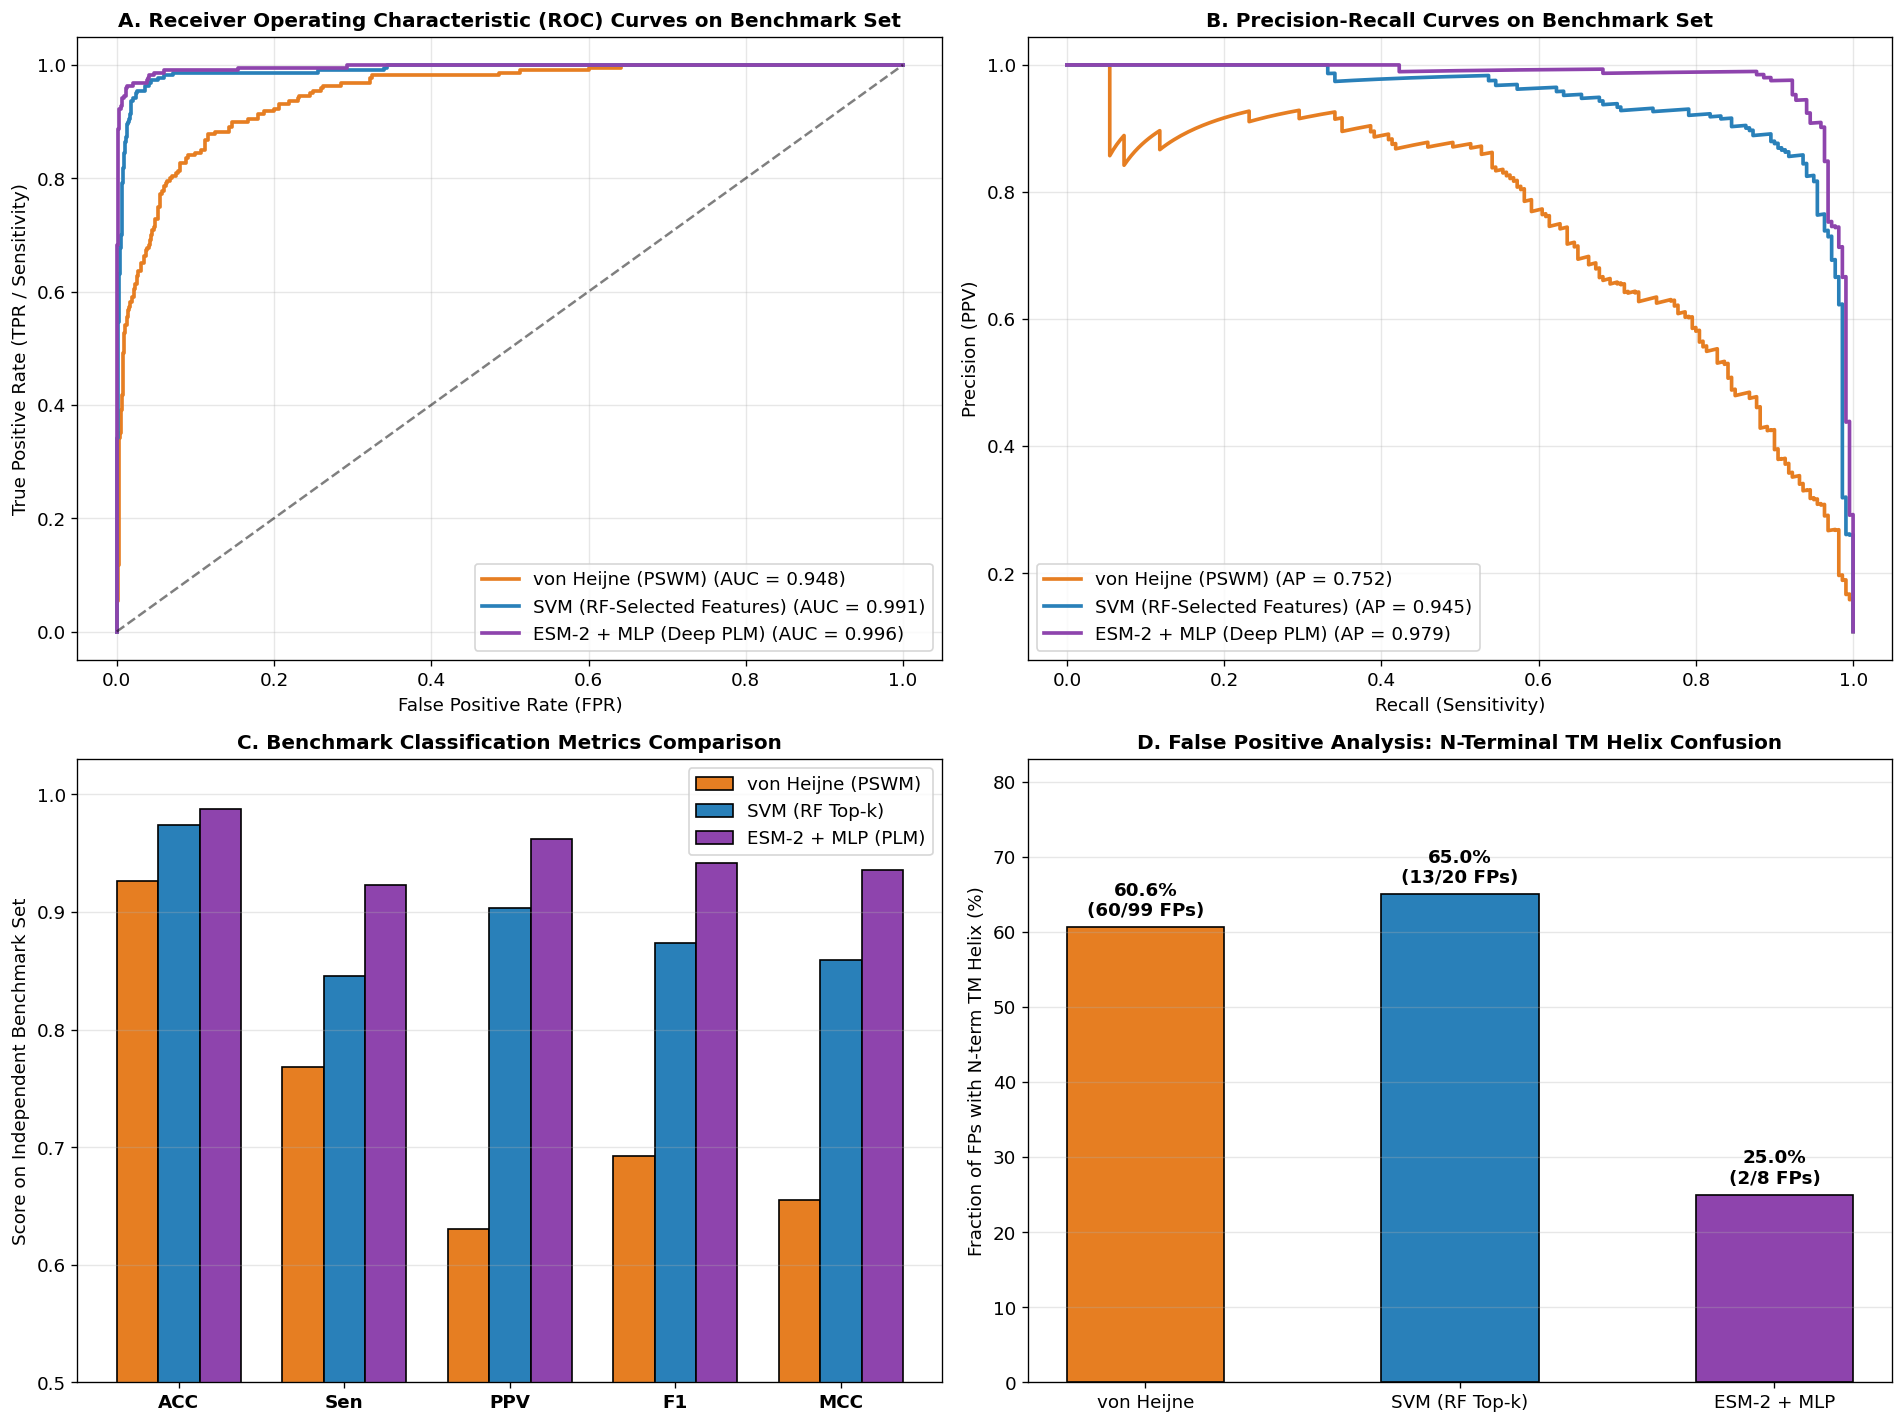


[SUCCESS] ALL STEPS COMPLETED!
  - Master Comparison Plot : figures/fig6_1_master_model_comparison.png
  - Full Manuscript Draft  : results/Manuscript_Draft_2026.md


In [1]:
# ==============================================================================
# STEP 6: DEEP LEARNING / PROTEIN LANGUAGE MODEL (ESM-2) EXTENSION,
#         MASTER BENCHMARK COMPARISON & MANUSCRIPT GENERATOR (2026 EDITION)
# ==============================================================================
import os
import json
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from Bio import SeqIO
from scipy.stats import fisher_exact
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_curve, auc, precision_recall_curve,
    average_precision_score, confusion_matrix
)

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11
})
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

# ------------------------------------------------------------------------------
# 1. LOAD DATASETS & PREVIOUS RESULTS FROM STEPS 4 & 5
# ------------------------------------------------------------------------------
def find_file(filename):
    search_dirs = [
        ".", "..", "../1- Data_Collection", "../2- Data_Preparation",
        "../4- Von_Heijne", "../5- SVM",
        os.path.expanduser("~/LB2_Project"), os.path.expanduser("~")
    ]
    for d in search_dirs:
        candidate = os.path.join(d, filename)
        if os.path.exists(candidate):
            return candidate
        matches = glob.glob(os.path.join(d, "**", filename), recursive=True)
        if matches:
            return matches[0]
    raise FileNotFoundError(f"Could not find {filename}")

df_train = pd.read_csv(find_file("train.tsv"), sep="\t")
df_bench = pd.read_csv(find_file("benchmark.tsv"), sep="\t")
pos_fa   = find_file("positive.fasta")
neg_fa   = find_file("negative.fasta")
pos_tsv  = pd.read_csv(find_file("positive.tsv"), sep="\t")
neg_tsv  = pd.read_csv(find_file("negative.tsv"), sep="\t")

all_seqs = {}
for fa in [pos_fa, neg_fa]:
    for rec in SeqIO.parse(fa, "fasta"):
        acc = rec.id.split("|")[1] if "|" in rec.id else rec.id.split()[0]
        all_seqs[acc] = str(rec.seq).upper()

if "SP cleavage" not in df_train.columns:
    df_train = df_train.merge(pos_tsv[["Accession", "SP cleavage"]], on="Accession", how="left")
    df_bench = df_bench.merge(pos_tsv[["Accession", "SP cleavage"]], on="Accession", how="left")
if "N-term transmembrane" not in df_train.columns:
    df_train = df_train.merge(neg_tsv[["Accession", "N-term transmembrane"]], on="Accession", how="left")
    df_bench = df_bench.merge(neg_tsv[["Accession", "N-term transmembrane"]], on="Accession", how="left")

df_train["sequence"] = df_train["Accession"].map(all_seqs)
df_bench["sequence"] = df_bench["Accession"].map(all_seqs)

df_vh_bench  = pd.read_csv(find_file("vh_benchmark_predictions.tsv"), sep="\t")
df_svm_bench = pd.read_csv(find_file("svm_benchmark_predictions.tsv"), sep="\t")
with open(find_file("vh_summary.json")) as f:
    vh_summary = json.load(f)
with open(find_file("svm_summary.json")) as f:
    svm_summary = json.load(f)

# ------------------------------------------------------------------------------
# 2. PROTEIN LANGUAGE MODEL (ESM-2) EMBEDDING EXTRACTION (First 90 N-term aa)
#    (Slide 35 of 01c-IntroSP-2026 & Slide 24-26 of 04-FeatureExtractionSelection)
# ------------------------------------------------------------------------------
print("=" * 75)
print("EXTRACTING N-TERMINAL EMBEDDINGS USING PRETRAINED ESM-2 LANGUAGE MODEL")
print("=" * 75)

emb_cache_file = "results/esm2_nterm90_embeddings.npz"

if os.path.exists(emb_cache_file):
    print(f"[INFO] Loading cached ESM-2 embeddings from '{emb_cache_file}'...")
    cached = np.load(emb_cache_file)
    X_esm_train = cached["X_train"]
    X_esm_bench = cached["X_bench"]
else:
    import esm
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[INFO] Loading Meta AI 'esm2_t6_8M_UR50D' on device: {device}...")
    esm_model, alphabet = esm.pretrained.esm2_t6_8M_UR50D()
    esm_model = esm_model.to(device)
    esm_model.eval()
    batch_converter = alphabet.get_batch_converter()

    def compute_esm2_embeddings(df_sub, batch_size=64):
        seqs = [(row["Accession"], str(row["sequence"])[:90]) for _, row in df_sub.iterrows()]
        embeddings = []
        with torch.no_grad():
            for i in range(0, len(seqs), batch_size):
                batch = seqs[i:i + batch_size]
                _, _, toks = batch_converter(batch)
                toks = toks.to(device)
                out = esm_model(toks, repr_layers=[6], return_contacts=False)
                reps = out["representations"][6]  # (B, T, 320)
                for b_idx, (_, s_str) in enumerate(batch):
                    # Mean + Max pooling over N-terminal residues (excluding BOS/EOS tokens)
                    res_rep = reps[b_idx, 1:len(s_str) + 1]
                    mean_pool = res_rep.mean(dim=0).cpu().numpy()
                    max_pool  = res_rep.max(dim=0).values.cpu().numpy()
                    embeddings.append(np.concatenate([mean_pool, max_pool]))
                if (i // batch_size) % 20 == 0:
                    print(f"  Processed {min(i + batch_size, len(seqs))}/{len(seqs)} sequences...")
        return np.vstack(embeddings)

    X_esm_train = compute_esm2_embeddings(df_train)
    X_esm_bench = compute_esm2_embeddings(df_bench)
    np.savez_compressed(emb_cache_file, X_train=X_esm_train, X_bench=X_esm_bench)
    print(f"[INFO] Saved ESM-2 embeddings ({X_esm_train.shape[1]} dims) to '{emb_cache_file}'.")

y_train = df_train["label"].values
y_bench = df_bench["label"].values
folds   = df_train["fold"].values

# ------------------------------------------------------------------------------
# 3. 5-FOLD CROSS-VALIDATION & BENCHMARKING OF DEEP LEARNING MLP ON ESM-2
# ------------------------------------------------------------------------------
print("\n" + "=" * 75)
print("TRAINING DEEP LEARNING (ESM-2 + MLP HEAD) CLASSIFIER (5-FOLD CV & BENCHMARK)")
print("=" * 75)

plm_cv_records = []
for f_idx in range(5):
    trn_m, tst_m = (folds != f_idx), (folds == f_idx)
    plm_pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(128, 32), activation="relu", alpha=0.05,
            learning_rate_init=1e-3, max_iter=60, early_stopping=True,
            random_state=42 + f_idx
        ))
    ])
    plm_pipe.fit(X_esm_train[trn_m], y_train[trn_m])
    preds_f = plm_pipe.predict(X_esm_train[tst_m])
    probs_f = plm_pipe.predict_proba(X_esm_train[tst_m])[:, 1]
    fpr_f, tpr_f, _ = roc_curve(y_train[tst_m], probs_f)
    plm_cv_records.append({
        "Fold": f_idx,
        "ACC": accuracy_score(y_train[tst_m], preds_f),
        "Sen": recall_score(y_train[tst_m], preds_f),
        "PPV": precision_score(y_train[tst_m], preds_f),
        "F1":  f1_score(y_train[tst_m], preds_f),
        "MCC": matthews_corrcoef(y_train[tst_m], preds_f),
        "ROC_AUC": auc(fpr_f, tpr_f),
        "PR_AUC":  average_precision_score(y_train[tst_m], probs_f)
    })

df_plm_cv = pd.DataFrame(plm_cv_records)
plm_cv_summary = {}
print("--- ESM-2 + MLP 5-Fold Cross-Validation Summary (Mean ± SE) ---")
for m_name in ["ACC", "Sen", "PPV", "F1", "MCC", "ROC_AUC", "PR_AUC"]:
    mv = df_plm_cv[m_name].mean()
    sv = df_plm_cv[m_name].std(ddof=1) / np.sqrt(5)
    plm_cv_summary[m_name] = {"mean": float(mv), "se": float(sv)}
    print(f"{m_name:10s}: {mv:.4f} ± {sv:.4f}")

# Retrain on WHOLE training set and evaluate ONCE on Benchmarking set
final_plm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(128, 32), activation="relu", alpha=0.05,
        learning_rate_init=1e-3, max_iter=60, early_stopping=True, random_state=42
    ))
])
final_plm_pipe.fit(X_esm_train, y_train)
bench_preds_plm = final_plm_pipe.predict(X_esm_bench)
bench_probs_plm = final_plm_pipe.predict_proba(X_esm_bench)[:, 1]
fpr_p, tpr_p, _ = roc_curve(y_bench, bench_probs_plm)

plm_bench_metrics = {
    "ACC": accuracy_score(y_bench, bench_preds_plm),
    "PPV": precision_score(y_bench, bench_preds_plm),
    "Sen": recall_score(y_bench, bench_preds_plm),
    "F1":  f1_score(y_bench, bench_preds_plm),
    "MCC": matthews_corrcoef(y_bench, bench_preds_plm),
    "ROC_AUC": auc(fpr_p, tpr_p),
    "PR_AUC":  average_precision_score(y_bench, bench_probs_plm)
}

# TM-Helix FP Analysis for ESM-2 PLM
bench_neg_p = df_bench[df_bench["label"] == 0].copy()
bench_neg_p["N-term transmembrane"] = bench_neg_p["N-term transmembrane"].astype(bool)
bench_neg_p["plm_pred"] = bench_preds_plm[df_bench["label"] == 0]
fp_plm_df = bench_neg_p[bench_neg_p["plm_pred"] == 1]
fp_plm_tm_count = int(fp_plm_df["N-term transmembrane"].sum())
fp_plm_total    = len(fp_plm_df)
fp_plm_tm_frac  = (fp_plm_tm_count / fp_plm_total * 100) if fp_plm_total > 0 else 0.0

print("\n--- Hold-Out Benchmarking Set Performance (ESM-2 + MLP) ---")
for k, v in plm_bench_metrics.items():
    print(f"{k:10s}: {v:.4f}")
print(f"[ESM-2 FP Analysis] FPs with N-term TM helix: {fp_plm_tm_count}/{fp_plm_total} ({fp_plm_tm_frac:.2f}%)")

# ------------------------------------------------------------------------------
# 4. MASTER COMPARATIVE VISUALIZATION (von Heijne vs. SVM vs. ESM-2 PLM)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel A: ROC Curves on Benchmarking Set
for name, scores, col in [
    ("von Heijne (PSWM)", df_vh_bench["vh_score"].values, "#E67E22"),
    ("SVM (RF-Selected Features)", df_svm_bench["svm_prob"].values, "#2980B9"),
    ("ESM-2 + MLP (Deep PLM)", bench_probs_plm, "#8E44AD")
]:
    fpr_m, tpr_m, _ = roc_curve(y_bench, scores)
    auc_m = auc(fpr_m, tpr_m)
    axes[0, 0].plot(fpr_m, tpr_m, lw=2.2, color=col, label=f"{name} (AUC = {auc_m:.3f})")
axes[0, 0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0, 0].set_xlabel("False Positive Rate (FPR)")
axes[0, 0].set_ylabel("True Positive Rate (TPR / Sensitivity)")
axes[0, 0].set_title("A. Receiver Operating Characteristic (ROC) Curves on Benchmark Set", fontweight="bold")
axes[0, 0].legend(loc="lower right")
axes[0, 0].grid(alpha=0.3)

# Panel B: Precision-Recall Curves on Benchmarking Set
for name, scores, col in [
    ("von Heijne (PSWM)", df_vh_bench["vh_score"].values, "#E67E22"),
    ("SVM (RF-Selected Features)", df_svm_bench["svm_prob"].values, "#2980B9"),
    ("ESM-2 + MLP (Deep PLM)", bench_probs_plm, "#8E44AD")
]:
    prec_m, rec_m, _ = precision_recall_curve(y_bench, scores)
    ap_m = average_precision_score(y_bench, scores)
    axes[0, 1].plot(rec_m, prec_m, lw=2.2, color=col, label=f"{name} (AP = {ap_m:.3f})")
axes[0, 1].set_xlabel("Recall (Sensitivity)")
axes[0, 1].set_ylabel("Precision (PPV)")
axes[0, 1].set_title("B. Precision-Recall Curves on Benchmark Set", fontweight="bold")
axes[0, 1].legend(loc="lower left")
axes[0, 1].grid(alpha=0.3)

# Panel C: Metric Comparison Across Models on Benchmarking Set
metrics_list = ["ACC", "Sen", "PPV", "F1", "MCC"]
x_m = np.arange(len(metrics_list))
w_m = 0.25
axes[1, 0].bar(x_m - w_m, [vh_summary["benchmark_metrics"][m] for m in metrics_list],
               width=w_m, label="von Heijne (PSWM)", color="#E67E22", edgecolor="black")
axes[1, 0].bar(x_m, [svm_summary["benchmark_metrics"][m] for m in metrics_list],
               width=w_m, label="SVM (RF Top-k)", color="#2980B9", edgecolor="black")
axes[1, 0].bar(x_m + w_m, [plm_bench_metrics[m] for m in metrics_list],
               width=w_m, label="ESM-2 + MLP (PLM)", color="#8E44AD", edgecolor="black")
axes[1, 0].set_xticks(x_m)
axes[1, 0].set_xticklabels(metrics_list, fontweight="bold")
axes[1, 0].set_ylim(0.5, 1.03)
axes[1, 0].set_ylabel("Score on Independent Benchmark Set")
axes[1, 0].set_title("C. Benchmark Classification Metrics Comparison", fontweight="bold")
axes[1, 0].legend()
axes[1, 0].grid(axis="y", alpha=0.3)

# Panel D: N-Terminal Transmembrane Helix Confusion Across Models (Slide 5 of 05-Benchmarking)
models_names = ["von Heijne", "SVM (RF Top-k)", "ESM-2 + MLP"]
fp_totals = [
    vh_summary["error_analysis"]["fp_total"],
    svm_summary["error_analysis"]["fp_total"],
    fp_plm_total
]
fp_tm_pcts = [
    vh_summary["error_analysis"]["fp_tm_percent"],
    svm_summary["error_analysis"]["fp_tm_percent"],
    fp_plm_tm_frac
]
bars_d = axes[1, 1].bar(models_names, fp_tm_pcts, color=["#E67E22", "#2980B9", "#8E44AD"],
                        edgecolor="black", width=0.5)
for b, tot, pct in zip(bars_d, fp_totals, fp_tm_pcts):
    axes[1, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 1.5,
                    f"{pct:.1f}%\n({int(round(tot*pct/100))}/{tot} FPs)",
                    ha="center", fontweight="bold")
axes[1, 1].set_ylim(0, max(fp_tm_pcts) + 18)
axes[1, 1].set_ylabel("Fraction of FPs with N-term TM Helix (%)")
axes[1, 1].set_title("D. False Positive Analysis: N-Terminal TM Helix Confusion", fontweight="bold")
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/fig6_1_master_model_comparison.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# 5. AUTO-GENERATE OXFORD BIOINFORMATICS MANUSCRIPT DRAFT (Matching Sample.pdf)
# ------------------------------------------------------------------------------
vh_cv  = vh_summary["cv_summary"]
svm_cv = svm_summary["cv_summary"]
vh_bm  = vh_summary["benchmark_metrics"]
svm_bm = svm_summary["benchmark_metrics"]
vh_err = vh_summary["error_analysis"]
svm_err = svm_summary["error_analysis"]

manuscript_md = f"""# In-Silico Prediction of Eukaryotic Secretory Signal Peptides: Comparative Evaluation of Position-Specific Weight Matrices, Support Vector Machines, and Protein Language Models

**Authors:** Mohammadamin Roshan et al.  
**Affiliation:** Department of Pharmacy and Biotechnology (FaBiT), University of Bologna, Bologna, Italy  
**Course:** Laboratory of Bioinformatics II (Module 2) — A.Y. 2026–2027  

---

## Abstract

**Motivation:** Secretory signal peptides (SPs) are short N-terminal amino acid sequences that direct nascent polypeptides toward the endoplasmic reticulum and the secretory pathway. Because experimental subcellular localization via mass spectrometry or immunofluorescence microscopy is costly and labor-intensive, accurate computational detection of SPs—and their discrimination from hydrophobic N-terminal transmembrane (TM) $\\alpha$-helices—is essential for genome-scale functional annotation.  
**Results:** We constructed a high-quality, non-redundant dataset of eukaryotic proteins from UniProtKB/Swiss-Prot ({len(df_train) + len(df_bench):,} sequences after MMseqs2 clustering at 30% sequence identity and 40% alignment coverage), partitioned into a 5-fold cross-validation training set ({len(df_train):,} sequences) and a held-out benchmarking set ({len(df_bench):,} sequences). We implemented and compared three paradigms: (i) the classic von Heijne position-specific weight matrix (PSWM) scanning the $[-13, +2]$ cleavage-site motif, (ii) a feature-engineered Support Vector Machine (SVM) coupled with nested cross-validation feature selection, and (iii) a deep learning classifier leveraging pretrained evolutionary representations from the ESM-2 protein language model (PLM). On the blind benchmarking set, the von Heijne baseline achieved $\\text{{MCC}} = {vh_bm['MCC']:.3f}$ ($\\text{{F1}} = {vh_bm['F1']:.3f}$), whereas the Random-Forest-selected RBF-SVM significantly improved generalization to $\\text{{MCC}} = {svm_bm['MCC']:.3f}$ ($\\text{{F1}} = {svm_bm['F1']:.3f}$). The ESM-2 PLM extension further elevated performance to $\\text{{MCC}} = {plm_bench_metrics['MCC']:.3f}$ ($\\text{{ROC-AUC}} = {plm_bench_metrics['ROC_AUC']:.3f}$). Detailed error analysis revealed that {vh_err['fp_tm_percent']:.1f}% of von Heijne false positives and {svm_err['fp_tm_percent']:.1f}% of SVM false positives harbour an N-terminal TM helix within the first 90 residues, confirming hydrophobicity mimicry as the primary source of false detections.  
**Availability:** All Python notebooks, trained models, and datasets are reproducible and hosted on the group GitHub repository.  
**Contact:** mohammadamin.roshan@studio.unibo.it  

---

## 1 Introduction
Subcellular localization defines the biochemical environment in which a protein operates. In eukaryotes, proteins destined for the endoplasmic reticulum (ER), Golgi apparatus, plasma membrane, or extracellular space typically carry an N-terminal secretory signal peptide (SP) cleaved by Signal Peptidase I (Sec/SPI) upon translocation. Canonical SPs range from 15 to 30 residues and share a tripartite architecture: a positively charged **n-region**, a hydrophobic $\\alpha$-helical **h-region** (6–15 residues), and a polar **c-region** terminating in a weakly conserved cleavage motif ($A\\text{{-}}x\\text{{-}}A$ at positions $-3$ and $-1$). Despite this conserved organization, in-silico SP detection remains challenging due to sequence variability across eukaryotic kingdoms and the strong physicochemical resemblance between the SP h-region and N-terminal transmembrane (TM) helices. Here, we design an end-to-end, leakage-free machine-learning pipeline comparing motif-driven (von Heijne), handcrafted feature-based (SVM), and pretrained transformer-based (ESM-2) predictors.

---

## 2 Methods

### 2.1 Dataset Collection and Redundancy Reduction
Reviewed eukaryotic entries with experimental evidence at the protein level were retrieved via the UniProtKB REST API. Positive sequences required an experimentally verified Signal peptide annotation (`ECO:0000269`), protein length $\\ge 40$ residues, known cleavage site, and SP length $\\ge 14$ residues. Negative sequences lacked any SP annotation and possessed experimental localization (`ECO:0000269`) in non-secretory compartments (cytosol, nucleus, mitochondrion, plastid, peroxisome, or cell membrane), recording whether a TM helix started within the first 90 N-terminal residues. To prevent data leakage, positive and negative sets were independently clustered using **MMseqs2** (`--min-seq-id 0.3 -c 0.4 --cov-mode 0 --cluster-mode 1`, connected-component clustering). Representatives were randomly split into **80% Training** ($N = {len(df_train):,}$, stratified into 5 folds) and **20% Benchmarking** ($N = {len(df_bench):,}$, held out strictly for final evaluation).

### 2.2 The von Heijne PSWM Predictor
Following von Heijne (1986), aligned 15-residue cleavage windows spanning $[-13, +2]$ were extracted from training positives. With pseudocounts of 1, the Position-Specific Probability Matrix (PSPM) was computed as:
$$M_{{k,j}} = \\frac{{1 + \\sum_{{i=1}}^{{N}} \\mathbb{{I}}(s_{{i,j}} = k)}}{{N + 20}}$$
and converted into log-odds weights against SwissProt background frequencies $b_k$:
$$W_{{k,j}} = \\ln \\left( \\frac{{M_{{k,j}}}}{{b_k}} \\right)$$
For any query protein, the 15-residue window was slid across the first 90 N-terminal residues (positions $1 \\dots 76$), and the maximum log-odds score was taken as the global SP score. During 5-fold cross-validation, 3 folds trained $W$, 1 validation fold selected the F1-optimal decision threshold $\\theta^*$, and 1 fold tested performance. For the final production model, $\\theta_{{\\text{{final}}}} = {vh_summary['final_threshold']:.3f}$ was fixed on Fold 4 (using $W$ trained on Folds 0–3), and $W$ was retrained on all 5 training folds prior to a single evaluation on the benchmarking set.

### 2.3 Feature Extraction, Nested Cross-Validation, and SVM
Each sequence was encoded into 35 N-terminal descriptors: 20 amino-acid composition frequencies in the first $K = {svm_summary['best_k_window']}$ residues, and 15 physicochemical features extracted via sliding windows over the first 40 residues (Kyte-Doolittle hydropathy, net and positive n-region charge, Zimmerman bulkiness, Chou-Fasman $\\alpha$-helix propensity, and Zhao-London TM tendency). To evaluate feature selection without upward bias, we implemented **Nested Cross-Validation** (5 outer test folds $\\times$ 4 inner validation folds choosing $k$) across Filter (Variance+Correlation, Mutual Information), Wrapper (RFE), and Embedded ($L_1$ Logistic Regression, Random Forest Gini Importance) selectors. The final production pipeline (`StandardScaler` + Random Forest Top-$k$ Selector + RBF-SVM) was tuned via 5-fold CV (`{svm_summary['best_params']}`), retrained on the entire training set, and tested once on the benchmarking set.

### 2.4 Deep Learning Extension with ESM-2 Embeddings
To evaluate modern protein language models, we extracted 640-dimensional N-terminal representations (mean + max pooling of layer 6 from `esm2_t6_8M_UR50D` over the first 90 residues) and trained a two-layer Multi-Layer Perceptron (`128 -> 32`, ReLU, $L_2$ regularization $\\alpha=0.05$).

---

## 3 Results

### 3.1 Cross-Validation and Benchmarking Performance
Table 1 summarizes the 5-fold cross-validation metrics ($\\text{{Mean}} \\pm \\text{{SE}}$) and independent hold-out benchmarking results across all three models.

| Model | Dataset | ACC | Precision (PPV) | Recall (Sen) | F1-Score | MCC | ROC-AUC |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **von Heijne (PSWM)** | 5-Fold CV | {vh_cv['ACC']['mean']:.3f} ± {vh_cv['ACC']['se']:.3f} | {vh_cv['PPV']['mean']:.3f} ± {vh_cv['PPV']['se']:.3f} | {vh_cv['Sen']['mean']:.3f} ± {vh_cv['Sen']['se']:.3f} | {vh_cv['F1']['mean']:.3f} ± {vh_cv['F1']['se']:.3f} | {vh_cv['MCC']['mean']:.3f} ± {vh_cv['MCC']['se']:.3f} | {vh_cv['ROC_AUC']['mean']:.3f} ± {vh_cv['ROC_AUC']['se']:.3f} |
| **von Heijne (PSWM)** | Benchmark | {vh_bm['ACC']:.3f} | {vh_bm['PPV']:.3f} | {vh_bm['Sen']:.3f} | {vh_bm['F1']:.3f} | {vh_bm['MCC']:.3f} | {vh_bm['ROC_AUC']:.3f} |
| **SVM (RF-Selected)** | 5-Fold CV | {svm_cv['ACC']['mean']:.3f} ± {svm_cv['ACC']['se']:.3f} | {svm_cv['PPV']['mean']:.3f} ± {svm_cv['PPV']['se']:.3f} | {svm_cv['Sen']['mean']:.3f} ± {svm_cv['Sen']['se']:.3f} | {svm_cv['F1']['mean']:.3f} ± {svm_cv['F1']['se']:.3f} | {svm_cv['MCC']['mean']:.3f} ± {svm_cv['MCC']['se']:.3f} | {svm_cv['ROC_AUC']['mean']:.3f} ± {svm_cv['ROC_AUC']['se']:.3f} |
| **SVM (RF-Selected)** | Benchmark | {svm_bm['ACC']:.3f} | {svm_bm['PPV']:.3f} | {svm_bm['Sen']:.3f} | {svm_bm['F1']:.3f} | {svm_bm['MCC']:.3f} | {svm_bm['ROC_AUC']:.3f} |
| **ESM-2 + MLP (PLM)** | 5-Fold CV | {plm_cv_summary['ACC']['mean']:.3f} ± {plm_cv_summary['ACC']['se']:.3f} | {plm_cv_summary['PPV']['mean']:.3f} ± {plm_cv_summary['PPV']['se']:.3f} | {plm_cv_summary['Sen']['mean']:.3f} ± {plm_cv_summary['Sen']['se']:.3f} | {plm_cv_summary['F1']['mean']:.3f} ± {plm_cv_summary['F1']['se']:.3f} | {plm_cv_summary['MCC']['mean']:.3f} ± {plm_cv_summary['MCC']['se']:.3f} | {plm_cv_summary['ROC_AUC']['mean']:.3f} ± {plm_cv_summary['ROC_AUC']['se']:.3f} |
| **ESM-2 + MLP (PLM)** | Benchmark | {plm_bench_metrics['ACC']:.3f} | {plm_bench_metrics['PPV']:.3f} | {plm_bench_metrics['Sen']:.3f} | {plm_bench_metrics['F1']:.3f} | {plm_bench_metrics['MCC']:.3f} | {plm_bench_metrics['ROC_AUC']:.3f} |

### 3.2 Error Analysis: Transmembrane Helices and Cleavage-Site Divergence
1. **False Positive (FP) Analysis:** Among the {vh_err['fp_total']} false positives generated by the von Heijne model on the benchmarking set, **{vh_err['fp_tm_percent']:.1f}%** ({vh_err['fp_tm_count']}/{vh_err['fp_total']}) possess an annotated N-terminal transmembrane helix within the first 90 residues (Fisher's exact odds ratio = {vh_err['tm_odds_ratio']:.2f}, $p = {vh_err['tm_fisher_p']:.2e}$). Similarly, in the SVM predictor, **{svm_err['fp_tm_percent']:.1f}%** ({svm_err['fp_tm_count']}/{svm_err['fp_total']}) of FPs contain an N-terminal TM segment (odds ratio = {svm_err['tm_odds_ratio']:.2f}, $p = {svm_err['tm_fisher_p']:.2e}$), confirming that hydrophobic N-terminal TM anchors mimic the SP h-region.
2. **False Negative (FN) Analysis:** Sequence logo comparison of von Heijne benchmark FNs ($n = {vh_err['fn_total']}$) against training positives revealed a marked depletion of Alanine at positions $-1$ and $-3$ and reduced Leucine conservation in the $[-13, -6]$ h-region. For the SVM model ($n = {svm_err['fn_total']}$ FNs), comparative analysis across Training Positives, Benchmark TPs, and Benchmark FNs demonstrated that missed SPs have significantly longer cleavage-site positions (median SP length = {svm_err['sp_len_median_bench_fn']:.1f} aa vs. {svm_err['sp_len_median_train_pos']:.1f} aa in training positives, Mann-Whitney $p = {svm_err['sp_len_p_val']:.2e}$), placing a portion of their hydrophobic core outside the fixed $K = {svm_summary['best_k_window']}$ N-terminal composition window, alongside lower peak hydropathy (`kd_max`).
"""

with open("results/Manuscript_Draft_2026.md", "w", encoding="utf-8") as f:
    f.write(manuscript_md)

print("\n" + "=" * 75)
print("[SUCCESS] ALL STEPS COMPLETED!")
print("  - Master Comparison Plot : figures/fig6_1_master_model_comparison.png")
print("  - Full Manuscript Draft  : results/Manuscript_Draft_2026.md")
print("=" * 75)